# EEG Analysis — Step 3B: Investigating Extreme Absolute ROI Power

**Purpose:** Trace unusually high ROI absolute-power observations back to the original channel-level EEG power outputs. This notebook is diagnostic only: it does not delete, transform, or exclude observations.

Outputs are saved in `eeg_step3B_extreme_investigation_outputs/`.

### Investigation questions
1. Are extreme ROI values reproducible as the mean of their mapped source channels?
2. Is an extreme ROI driven by one electrode or several electrodes?
3. Are high values specific to Delta or present across bands?
4. Are values concentrated in specific participants/recordings/regions?

A statistical flag is **not** automatically an EEG artifact. Decisions about rejection require signal-level review and documented criteria.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---- Locate project files (works from analysis folder or a parent project folder) ----
CWD = Path.cwd()
SEARCH_ROOTS = [CWD, Path('/mnt/data')]
for parent in CWD.parents:
    SEARCH_ROOTS.append(parent)

def find_file(filename):
    candidates = []
    for root in SEARCH_ROOTS:
        if root.exists():
            candidates.extend(root.rglob(filename))
    if candidates:
        # Prefer a path that is inside an analysis folder, then shortest path.
        candidates = sorted(set(candidates), key=lambda p: (('analysis' not in str(p).lower()), len(str(p))))
        return candidates[0]
    raise FileNotFoundError(f'Could not locate {filename}. Place the file in the project Results or analysis folder.')

FLAGS_FILE = find_file('eeg_power_extreme_flags.csv')
ROI_LONG_FILE = find_file('eeg_roi_power_long.csv')
MAPPING_FILE = find_file('eeg_roi_channel_mapping_DRAFT_REVISED.csv')
OUTPUT_DIR = Path('eeg_step3B_extreme_investigation_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Flags:', FLAGS_FILE)
print('ROI table:', ROI_LONG_FILE)
print('Mapping:', MAPPING_FILE)
print('Output folder:', OUTPUT_DIR.resolve())

Flags: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3A_distribution_audit_outputs/eeg_power_extreme_flags.csv
ROI table: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Mapping: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_channel_mapping_DRAFT_REVISED.csv
Output folder: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3B_extreme_investigation_outputs


In [2]:
flags = pd.read_csv(FLAGS_FILE)
roi_long = pd.read_csv(ROI_LONG_FILE)
roi_map = pd.read_csv(MAPPING_FILE)
roi_map.columns = roi_map.columns.astype(str).str.strip().str.lower()

required_map = {'channel','roi'}
if not required_map.issubset(roi_map.columns):
    raise ValueError(f'Mapping file must contain columns {required_map}; found {roi_map.columns.tolist()}')
roi_map['channel'] = roi_map['channel'].astype(str).str.strip().str.upper()
roi_map['roi'] = roi_map['roi'].astype(str).str.strip()

flags['session'] = flags['session'].astype(str).str.upper()
roi_long['session'] = roi_long['session'].astype(str).str.upper()
flags['band'] = flags['band'].astype(str).str.lower()
roi_long['band'] = roi_long['band'].astype(str).str.lower()
flags['condition'] = flags['condition'].astype(str).str.strip()
roi_long['condition'] = roi_long['condition'].astype(str).str.strip()

abs_flags = flags[(flags['metric'] == 'absolute_power_roi') & flags['any_flag'].astype(bool)].copy()
print('Flagged absolute ROI observations:', len(abs_flags))
print('Flagged unique participants:', abs_flags.subject_id.nunique())
print('Flagged by band:')
display(abs_flags.groupby('band').size().sort_values(ascending=False).to_frame('flagged_records'))

Flagged absolute ROI observations: 2580
Flagged unique participants: 62
Flagged by band:


,flagged_records
band,
alpha,528
theta,518
gamma,517
beta,510
delta,507


## 1. Top flagged ROI observations

In [3]:
top_extremes = abs_flags.sort_values('value', ascending=False).head(100).copy()
cols = ['subject_id','task','group','session','run','condition','band','roi','value','iqr_flag','mad_flag']
top_extremes[cols].head(30).to_csv(OUTPUT_DIR/'top_30_flagged_absolute_roi_observations.csv', index=False)
display(top_extremes[cols].head(30))

,subject_id,task,group,session,run,condition,band,roi,value,iqr_flag,mad_flag
4116,Mc09,Math,Control,PRE,1,Baseline,delta,Occipital,8.617234e+09,True,True
13014,Re09,Reading,Experiment,POST,2,Activity,delta,Occipital,5.424984e+09,True,True
8765,Me10,Math,Experiment,PRE,3,Activity2,delta,Occipital,4.729225e+09,True,True
1119,Mc12,Math,Control,POST,3,Activity2,delta,Occipital,4.421564e+09,True,True
4959,Me04,Math,Experiment,POST,2,Activity1,delta,Occipital,3.308835e+09,True,True
3364,Mc06,Math,Control,PRE,3,Activity2,delta,Occipital,3.137039e+09,True,True
8770,Me15,Math,Experiment,PRE,3,Activity2,delta,Occipital,3.031365e+09,True,True
4146,Mc09,Math,Control,PRE,1,Baseline,delta,Parietal,3.029976e+09,True,True
8803,Me10,Math,Experiment,PRE,3,Activity2,delta,Parietal,2.964936e+09,True,True
5909,Me04,Math,Experiment,POST,3,Activity2,delta,Occipital,2.561780e+09,True,True


## 2. Load original channel-level source files

In [4]:
# File naming expected: eeg_analysis_results_<task>_<group>.csv
source_specs = {
    'Math_Control': ('Math','Control','eeg_analysis_results_math_control.csv'),
    'Math_Experiment': ('Math','Experiment','eeg_analysis_results_math_experiment.csv'),
    'Reading_Control': ('Reading','Control','eeg_analysis_results_read_control.csv'),
    'Reading_Experiment': ('Reading','Experiment','eeg_analysis_results_read_experiment.csv'),
}
source_frames = []
for label, (task, group, fname) in source_specs.items():
    try:
        path = find_file(fname)
    except FileNotFoundError:
        # Try common alternate prefix.
        alt = fname.replace('eeg_analysis_results_', 'eeg_analysis_')
        path = find_file(alt)
    df = pd.read_csv(path)
    df['task'] = task
    df['group'] = group
    df['session'] = df['session'].astype(str).str.lower().replace({'ses-1':'PRE','ses-2':'POST'}).str.upper()
    df['condition'] = df['condition'].astype(str).str.strip()
    df['band'] = df['band'].astype(str).str.lower()
    df['channel'] = df['channel'].astype(str).str.strip().str.upper()
    source_frames.append(df)
    print(label, path, 'rows=',len(df))
channel_power = pd.concat(source_frames, ignore_index=True)
print('Combined source rows:', len(channel_power))
print('Bands:', sorted(channel_power.band.unique()))
print('Channels:', channel_power.channel.nunique())

Math_Control /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv rows= 14400
Math_Experiment /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_experiment.csv rows= 18240
Reading_Control /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_read_control.csv rows= 7680
Reading_Experiment /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_read_experiment.csv rows= 10880
Combined source rows: 51200
Bands: ['alpha', 'beta', 'delta', 'gamma', 'theta']
Channels: 32


## 3. Trace flagged ROI observations to mapped electrodes

In [5]:
# Join keys identifying one participant/session/run/condition/band.
trace_keys = ['subject_id','task','group','session','run','condition','band']
# Keep only top 100 extreme flagged ROI observations for detailed trace.
trace_targets = abs_flags.sort_values('value', ascending=False).head(100).copy()
# Filter channel-level source data per target key and mapped ROI channel.
trace_rows = []
for _, target in trace_targets.iterrows():
    mask = np.ones(len(channel_power), dtype=bool)
    for k in trace_keys:
        mask &= channel_power[k].astype(str).eq(str(target[k])).to_numpy()
    mask &= channel_power['channel'].isin(roi_map.loc[roi_map.roi.eq(target['roi']),'channel']).to_numpy()
    matched = channel_power.loc[mask, ['channel','absolute_power','relative_power','frequency_min','frequency_max']].copy()
    if matched.empty:
        trace_rows.append({**{k:target[k] for k in trace_keys}, 'roi':target['roi'], 'roi_power_reported':target['value'],
                         'source_channel_count':0, 'source_channel_mean':np.nan, 'source_channel_median':np.nan,
                         'source_channel_max':np.nan, 'max_channel':None, 'mean_abs_diff':np.nan, 'trace_status':'NO_SOURCE_MATCH'})
        continue
    matched['channel'] = matched.channel.astype(str)
    matched = matched.merge(roi_map, on='channel', how='left')
    # Keep channel details separately, with target record identifier.
    target_id = f"{target['subject_id']}_{target.task}_{target.session}_{target.run}_{target.condition}_{target.band}_{target['roi']}"
    matched['trace_target_id'] = target_id
    matched['target_roi_value'] = target['value']
    matched['target_roi'] = target['roi']
    matched['target_subject'] = target['subject_id']
    matched['target_group'] = target['group']
    matched['target_task'] = target.task
    matched['target_session'] = target.session
    matched['target_condition'] = target.condition
    matched['target_run'] = target.run
    matched['target_band'] = target.band
    trace_rows.append({'_detail':matched})

# Split detail and summary rows
channel_details = [x['_detail'] for x in trace_rows if '_detail' in x]
trace_summary_rows = []
for item in trace_rows:
    if '_detail' in item:
        d=item['_detail']
        target=d.iloc[0]
        vals=d.absolute_power.astype(float)
        roi_recalc=vals.mean()
        trace_summary_rows.append({'subject_id':target.target_subject,'task':target.target_task,'group':target.target_group,
            'session':target.target_session,'run':target.target_run,'condition':target.target_condition,'band':target.target_band,
            'roi':target.target_roi,'roi_power_reported':target.target_roi_value,'source_channel_count':len(d),
            'source_channel_mean':roi_recalc,'source_channel_median':vals.median(),'source_channel_max':vals.max(),
            'max_channel':d.loc[d.absolute_power.idxmax(),'channel'],
            'mean_abs_diff':abs(roi_recalc-target.target_roi_value),'trace_status':'MATCHED'})
    else:
        trace_summary_rows.append(item)
trace_summary = pd.DataFrame(trace_summary_rows)
channel_detail = pd.concat(channel_details, ignore_index=True) if channel_details else pd.DataFrame()
trace_summary.to_csv(OUTPUT_DIR/'top_100_extreme_roi_channel_trace_summary.csv', index=False)
channel_detail.to_csv(OUTPUT_DIR/'top_100_extreme_roi_channel_details.csv', index=False)
display(trace_summary.head(20))
print('Trace summary rows:',len(trace_summary),'Channel detail rows:',len(channel_detail))

,subject_id,task,group,session,run,condition,band,roi,roi_power_reported,source_channel_count,source_channel_mean,source_channel_median,source_channel_max,max_channel,mean_abs_diff,trace_status
0,Mc09,Math,Control,PRE,1,Baseline,delta,Occipital,8.617234e+09,3,8.617234e+09,9.679826e+09,1.155827e+10,O1,0.000000e+00,MATCHED
1,Re09,Reading,Experiment,POST,2,Activity,delta,Occipital,5.424984e+09,3,5.424984e+09,1.995444e+09,1.268992e+10,OZ,0.000000e+00,MATCHED
2,Me10,Math,Experiment,PRE,3,Activity2,delta,Occipital,4.729225e+09,3,4.729225e+09,1.935041e+09,1.032975e+10,O1,0.000000e+00,MATCHED
3,Mc12,Math,Control,POST,3,Activity2,delta,Occipital,4.421564e+09,3,4.421564e+09,4.857693e+09,5.912476e+09,O1,0.000000e+00,MATCHED
4,Me04,Math,Experiment,POST,2,Activity1,delta,Occipital,3.308835e+09,3,3.308835e+09,3.747751e+09,5.775664e+09,OZ,0.000000e+00,MATCHED
5,Mc06,Math,Control,PRE,3,Activity2,delta,Occipital,3.137039e+09,3,3.137039e+09,2.543990e+09,6.594896e+09,OZ,0.000000e+00,MATCHED
6,Me15,Math,Experiment,PRE,3,Activity2,delta,Occipital,3.031365e+09,3,3.031365e+09,2.947486e+09,5.168847e+09,OZ,0.000000e+00,MATCHED
7,Mc09,Math,Control,PRE,1,Baseline,delta,Parietal,3.029976e+09,9,3.029976e+09,2.293006e+08,1.166019e+10,CP6,0.000000e+00,MATCHED
8,Me10,Math,Experiment,PRE,3,Activity2,delta,Parietal,2.964936e+09,9,2.964936e+09,1.021314e+06,1.274860e+10,CP6,4.768372e-07,MATCHED
9,Me04,Math,Experiment,POST,3,Activity2,delta,Occipital,2.561780e+09,3,2.561780e+09,2.768806e+09,4.385603e+09,OZ,0.000000e+00,MATCHED


Trace summary rows: 100 Channel detail rows: 526


## 4. Verify ROI aggregation against source channels

In [6]:
# Efficiently recalculate ROI means by joining channels to ROI mapping, then group once.
source_with_roi = channel_power.merge(roi_map[['channel','roi']], on='channel', how='inner')
agg_keys = ['subject_id','task','group','session','run','condition','band','roi']
source_roi_means = (source_with_roi.groupby(agg_keys, as_index=False)
                    .agg(source_n=('absolute_power','count'), recalculated_mean=('absolute_power','mean')))
recalc = roi_long[agg_keys + ['absolute_power_roi']].merge(source_roi_means, on=agg_keys, how='left')
recalc['stored_roi_mean'] = recalc['absolute_power_roi']
recalc['absolute_difference'] = (recalc['recalculated_mean'] - recalc['stored_roi_mean']).abs()
recalc.to_csv(OUTPUT_DIR/'roi_aggregation_source_recalculation_audit.csv', index=False)
print('Recalculation records:',len(recalc))
print('Max abs difference:',recalc.absolute_difference.max())
print('Records with difference > 1e-6:',int((recalc.absolute_difference>1e-6).sum()))
display(recalc.sort_values('absolute_difference',ascending=False).head(10))

Recalculation records: 8000
Max abs difference: 2.384185791015625e-07
Records with difference > 1e-6: 0


,subject_id,task,group,session,run,condition,band,roi,absolute_power_roi,source_n,recalculated_mean,stored_roi_mean,absolute_difference
1413,Mc12,Math,Control,POST,3,Activity2,delta,Parietal,1.232130e+09,9,1.232130e+09,1.232130e+09,2.384186e-07
7088,Re10,Reading,Experiment,PRE,2,Activity,delta,Parietal,1.309621e+09,9,1.309621e+09,1.309621e+09,2.384186e-07
5988,Rc10,Reading,Control,PRE,2,Activity,delta,Parietal,1.855642e+09,9,1.855642e+09,1.855642e+09,2.384186e-07
3887,Me11,Math,Experiment,PRE,3,Activity2,delta,Occipital,1.425116e+09,3,1.425116e+09,1.425116e+09,2.384186e-07
3039,Me06,Math,Experiment,POST,2,Activity1,delta,Temporal,9.772984e+08,6,9.772984e+08,9.772984e+08,1.192093e-07
6313,Re01,Reading,Experiment,POST,1,Baseline,delta,Parietal,9.318047e+08,9,9.318047e+08,9.318047e+08,1.192093e-07
6862,Re08,Reading,Experiment,PRE,1,Baseline,delta,Occipital,1.032957e+09,3,1.032957e+09,1.032957e+09,1.192093e-07
3438,Me08,Math,Experiment,PRE,3,Activity2,delta,Parietal,9.199865e+08,9,9.199865e+08,9.199865e+08,1.192093e-07
2513,Me02,Math,Experiment,PRE,2,Activity1,delta,Parietal,3.664752e+08,9,3.664752e+08,3.664752e+08,5.960464e-08
7087,Re10,Reading,Experiment,PRE,2,Activity,delta,Occipital,4.396302e+08,3,4.396302e+08,4.396302e+08,5.960464e-08


## 5. Channel-level distribution within extreme ROI blocks

In [7]:
# Summarize channel spread across the top flagged ROI blocks.
if not channel_detail.empty:
    channel_stats=(channel_detail.groupby(['target_subject','target_task','target_session','target_run','target_condition','target_band','target_roi'])
        .agg(n_channels=('absolute_power','count'),channel_min=('absolute_power','min'),channel_median=('absolute_power','median'),
             channel_mean=('absolute_power','mean'),channel_max=('absolute_power','max'),channel_sd=('absolute_power','std'))
        .reset_index())
    channel_stats['max_to_median_ratio']=channel_stats.channel_max/channel_stats.channel_median.replace(0,np.nan)
    channel_stats.to_csv(OUTPUT_DIR/'top_extreme_roi_channel_spread_summary.csv',index=False)
    display(channel_stats.sort_values('max_to_median_ratio',ascending=False).head(25))
else:
    print('Channel detail table empty; cannot summarize spread.')

,target_subject,target_task,target_session,target_run,target_condition,target_band,target_roi,n_channels,channel_min,channel_median,channel_mean,channel_max,channel_sd,max_to_median_ratio
66,Rc03,Reading,POST,2,Activity,delta,Parietal,9,1.549912,3.070664,6.945967e+08,5.976454e+09,1.982782e+09,1.946307e+09
96,Re18,Reading,PRE,2,Activity,delta,Temporal,6,2.191133,7.571992,8.346404e+08,5.007842e+09,2.044443e+09,6.613639e+08
83,Re01,Reading,PRE,2,Activity,delta,Temporal,6,2.334880,8.416493,7.996041e+08,4.783318e+09,1.951622e+09,5.683267e+08
94,Re10,Reading,PRE,2,Activity,delta,Parietal,9,186.215245,287.525192,1.309621e+09,1.178515e+10,3.928323e+09,4.098823e+07
79,Rc16,Reading,POST,1,Baseline,delta,Occipital,3,20.201737,83.484721,7.083910e+08,2.125173e+09,1.226969e+09,2.545583e+07
2,Mc03,Math,POST,3,Activity2,delta,Temporal,6,239.719153,404.511566,1.140104e+09,6.840623e+09,2.792672e+09,1.691082e+07
1,Mc03,Math,POST,2,Activity1,delta,Temporal,6,95.872294,312.929565,8.229475e+08,4.937684e+09,2.015801e+09,1.577890e+07
87,Re04,Reading,PRE,2,Activity,delta,Parietal,9,497.275492,650.818085,7.086010e+08,6.377401e+09,2.125800e+09,9.799053e+06
21,Mc19,Math,POST,1,Baseline,delta,Temporal,6,65.555216,475.772652,7.258690e+08,4.355212e+09,1.778008e+09,9.153976e+06
81,Re01,Reading,POST,1,Baseline,delta,Parietal,9,713.986734,835.279475,9.318047e+08,7.259650e+09,2.401895e+09,8.691283e+06


## 6. Cross-band profile of the participants with the most extreme values

In [8]:
# Select the 20 participants appearing most often in top 100 extreme ROI observations.
if len(trace_summary):
    top_subjects=trace_summary.subject_id.value_counts().head(20).index.tolist()
    profiles=roi_long[roi_long.subject_id.isin(top_subjects)].copy()
    profiles.to_csv(OUTPUT_DIR/'top_extreme_subjects_all_roi_power_profiles.csv',index=False)
    # Participant-level maxima by metric/band/ROI for descriptive context.
    prof_summary=(profiles.groupby(['subject_id','task','group','session','condition','band','roi'])
        .agg(absolute_power_mean=('absolute_power_roi','mean'),absolute_power_max=('absolute_power_roi','max'),
             relative_power_mean=('relative_power_roi','mean'),relative_power_max=('relative_power_roi','max'))
        .reset_index())
    prof_summary.to_csv(OUTPUT_DIR/'top_extreme_subjects_band_roi_profile_summary.csv',index=False)
    display(prof_summary.head(30))

,subject_id,task,group,session,condition,band,roi,absolute_power_mean,absolute_power_max,relative_power_mean,relative_power_max
0,Mc06,Math,Control,POST,Activity1,alpha,Central,2.775922e+04,2.775922e+04,4.063753,4.063753
1,Mc06,Math,Control,POST,Activity1,alpha,Frontal,3.457380e+04,3.457380e+04,3.158048,3.158048
2,Mc06,Math,Control,POST,Activity1,alpha,Occipital,6.743062e+05,6.743062e+05,2.895325,2.895325
3,Mc06,Math,Control,POST,Activity1,alpha,Parietal,1.711776e+05,1.711776e+05,5.510323,5.510323
4,Mc06,Math,Control,POST,Activity1,alpha,Temporal,2.948474e+04,2.948474e+04,4.016878,4.016878
5,Mc06,Math,Control,POST,Activity1,beta,Central,2.048445e+04,2.048445e+04,5.873481,5.873481
6,Mc06,Math,Control,POST,Activity1,beta,Frontal,2.384358e+04,2.384358e+04,2.178484,2.178484
7,Mc06,Math,Control,POST,Activity1,beta,Occipital,6.375668e+05,6.375668e+05,2.221258,2.221258
8,Mc06,Math,Control,POST,Activity1,beta,Parietal,1.220440e+05,1.220440e+05,11.136118,11.136118
9,Mc06,Math,Control,POST,Activity1,beta,Temporal,2.177996e+04,2.177996e+04,5.586234,5.586234


## 7. Diagnostic visualizations

<Figure size 1200x600 with 0 Axes>

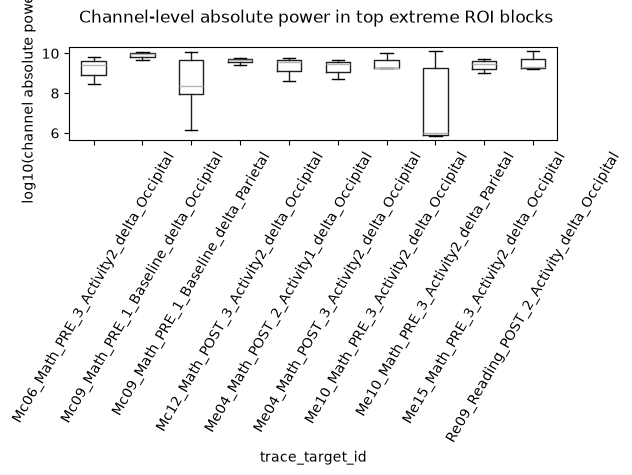

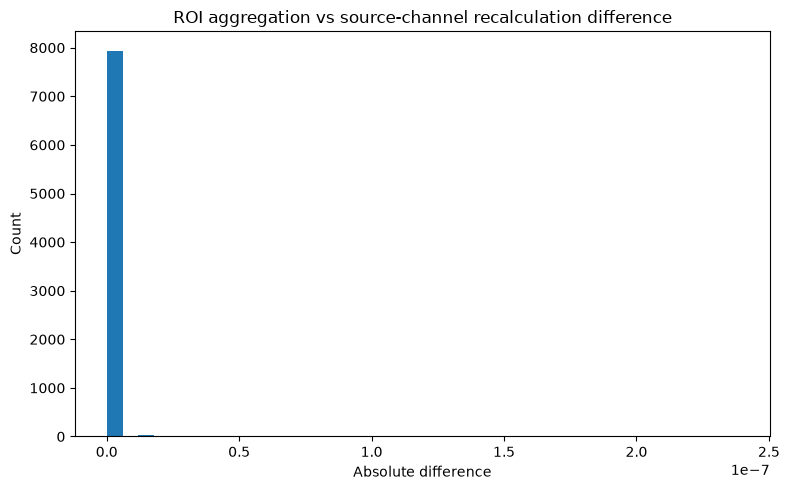

In [9]:
# Channel-wise values for top 10 flagged blocks, log10 scale, with zero/nonpositive guarded.
if not channel_detail.empty:
    plot_df=channel_detail.copy()
    plot_df['log10_absolute_power']=np.log10(plot_df.absolute_power.clip(lower=np.finfo(float).tiny))
    groups=(plot_df.groupby(['target_subject','target_session','target_condition','target_band','target_roi','trace_target_id'])
           .agg(channel_mean=('log10_absolute_power','mean'),channel_max=('log10_absolute_power','max')).reset_index())
    top_ids=trace_summary.sort_values('roi_power_reported',ascending=False).head(10)
    idset=set(top_ids.apply(lambda r:f"{r.subject_id}_{r.task}_{r.session}_{r.run}_{r.condition}_{r.band}_{r.roi}",axis=1))
    view=plot_df[plot_df.trace_target_id.isin(idset)]
    if len(view):
        plt.figure(figsize=(12,6))
        view.boxplot(column='log10_absolute_power',by='trace_target_id',rot=60,grid=False)
        plt.suptitle('Channel-level absolute power in top extreme ROI blocks')
        plt.title('')
        plt.ylabel('log10(channel absolute power)')
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR/'top_10_extreme_blocks_channel_power_boxplot.png',dpi=200,bbox_inches='tight')
        plt.show()

# Histogram of recalculation differences, if available
finite_diffs = recalc.absolute_difference.dropna()
if len(finite_diffs):
    plt.figure(figsize=(8,5))
    plt.hist(finite_diffs, bins=40)
    plt.title('ROI aggregation vs source-channel recalculation difference')
    plt.xlabel('Absolute difference')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'roi_aggregation_recalculation_difference_histogram.png',dpi=200,bbox_inches='tight')
    plt.show()

## 8. Diagnostic summary and next decision

In [10]:
# Export a compact summary for review
summary = {
    'flagged_absolute_roi_records': int(len(abs_flags)),
    'flagged_absolute_roi_participants': int(abs_flags.subject_id.nunique()),
    'top_100_trace_records': int(len(trace_summary)),
    'matched_trace_records': int((trace_summary.trace_status=='MATCHED').sum()) if 'trace_status' in trace_summary else 0,
    'no_source_match_records': int((trace_summary.trace_status=='NO_SOURCE_MATCH').sum()) if 'trace_status' in trace_summary else 0,
    'aggregation_recalculation_records': int(len(recalc)),
    'aggregation_recalculation_max_abs_difference': float(recalc.absolute_difference.max()) if len(recalc) else np.nan,
    'aggregation_recalculation_mismatches_gt_1e-6': int((recalc.absolute_difference>1e-6).sum()) if len(recalc) else np.nan,
}
pd.DataFrame([summary]).to_csv(OUTPUT_DIR/'step3B_diagnostic_summary.csv',index=False)
print(summary)
print('Saved outputs to:',OUTPUT_DIR.resolve())

{'flagged_absolute_roi_records': 2580, 'flagged_absolute_roi_participants': 62, 'top_100_trace_records': 100, 'matched_trace_records': 100, 'no_source_match_records': 0, 'aggregation_recalculation_records': 8000, 'aggregation_recalculation_max_abs_difference': 2.384185791015625e-07, 'aggregation_recalculation_mismatches_gt_1e-6': 0}
Saved outputs to: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3B_extreme_investigation_outputs


## Interpretation guardrails

- This audit can establish whether the ROI values are reproducible from channel-level inputs and whether one or more channels dominate an ROI average.
- It cannot establish artifact causation from band-power values alone. Artifact confirmation requires inspecting raw/filtered EEG traces and/or preprocessing QC (e.g., bad-channel, clipping, drift, ocular/muscle contamination, impedance or rejection records, as available).
- Do not exclude flagged participants or observations at this stage. Record candidate cases for signal-level review.
- If aggregation matches source channels but the absolute-power scale is still unexpectedly high, the next investigation should audit units, PSD normalization, frequency-bin integration, and preprocessing settings before choosing transformations or inferential outcomes.